# Top-of-atmosphere simulations with RadCalNet-OC for TRISHNA

## Requirements
- The AERONET-OC database (`aeronet_oc_db`); optionally the hyperspectral invRrs reconstruction of the AERONET-OC spectra.
- The radcalnet_oc look-up tables (`radcalnet_oc_config --download`).

## Tutorial objectives
- Propagate in situ water-leaving reflectances (AERONET-OC, Venice) to the top of the atmosphere.
- Convolve the hyperspectral TOA signal with the TRISHNA and Sentinel-2 responses.
- Derive Sentinel-2 -> TRISHNA band adjustment factors at TOA.
- Analyse the sensitivity of the TRISHNA bands to aerosols, water vapour and aerosol type.

## Environment
Use the `sandbox_env` kernel of the CNES JupyterHub. Otherwise install the packages below in your environment (the `trishna_tbx` toolbox: `pip install -e <path>/trishna_tbx`):

`GRSdriver`, `grs`, `GRSl2bgen`, `radcalnet_oc`, `invRrs`, `trishna_tbx`, `matplotlib`, `pandas`, `xarray`.

## Resources
The code can be executed with the CPU: 4 cores, 8 GB. Run time: ~6 min.

![version](https://img.shields.io/badge/version-11.2026-blue)

## Imports

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

import trishna_tbx
from trishna_tbx import TRISHNA, make_s2
print('trishna_tbx', trishna_tbx.__version__)
from pathlib import Path
THUMB_DIR = Path('../thumbnails').resolve() if Path('../thumbnails').exists() else Path('.').resolve()
plt.rcParams.update({'figure.dpi': 90, 'font.size': 11})

from trishna_tbx.simulate import aeronet_oc_input, simulate_toa, to_sensors, sensitivity_grid, build_input
from trishna_tbx.emulate import SBAF
from radcalnet_oc.process import AEROSOL_MODELS

trishna_tbx 0.0.1


## Data
> **Data paths.** On the CNES JupyterHub, point the variables below to the TREX datalake or to your project space. Outside CNES, download Sentinel-2 L1C with the *Access data - Copernicus API* tutorial. Each path can also be set through the environment variable named in the cell.

In [2]:
import os
from pathlib import Path

# ---- edit here (or set the environment variables) ------------------------------------
S2_L1C = os.environ.get('TRISHNA_TBX_S2_L1C',
    '/data/satellite/Sentinel-2/L1C/31TFJ/2025/05/26/'
    'S2B_MSIL1C_20250526T103629_N0511_R008_T31TFJ_20250526T123708.SAFE')
CAMS_FILE = os.environ.get('TRISHNA_TBX_CAMS', '/data/cams/world/cams_forecast_2025-05.nc')
# 30 km box (UTM 31N) over the Berre lagoon and the eastern Gulf of Fos
SUBSET = [(655000, 4800000, 685000, 4830000)]
L2A_DIR = os.environ.get('TRISHNA_TBX_L2A_DIR',
    '/home/harmel/Dropbox/Dropbox/work/projet/unesco/satellite/L2A')  # GRS L2A (beam profile)
L2A_TILE = 'T33PVQ'                      # Lake Chad (southern pool)
L2A_WINDOW = 'y=0:3600,x=0:960'          # 20 m pixel window with water
L2A_DATE = '2022-02-12'                  # date used by the single-image tutorials
AERONET_HYP_DIR = os.environ.get('TRISHNA_TBX_AERONET_HYP', '/DATA/AERONET/OCv3_invRrs/data')
OUTPUT_DIR = Path(os.environ.get('TRISHNA_TBX_OUTPUT', './output')).resolve()
# ---------------------------------------------------------------------------------------
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## 1. In situ water reflectance: AERONET-OC Venice
RadCalNet-OC (radcalnet_oc) takes the water reflectance and the atmospheric state measured
at the site (aerosol optical thickness, water vapour, ozone, NO2, pressure, wind) for each
record. The SeaPRISM multispectral Rrs is replaced by its hyperspectral reconstruction
(invRrs) when available.

In [3]:
SITE, PERIOD = 'Venise', slice('2021-05', '2021-09')
hyp = AERONET_HYP_DIR if Path(AERONET_HYP_DIR).exists() else None
inp = aeronet_oc_input(SITE, PERIOD, hyp_dir=hyp, max_records=40)
print(f'{inp.sizes["time"]} records; hyperspectral: {hyp is not None}')
inp[['sza', 'aot550', 'ang_exp', 'tcwv', 'tco3', 'pressure', 'wind', 'chl_aeronet']].to_dataframe().describe().round(3)

40 records; hyperspectral: True


,sza,aot550,ang_exp,tcwv,tco3,pressure,wind,chl_aeronet
count,40.000,40.000,40.000,40.000,40.000,40.000,40.000,40.000
mean,32.349,0.091,1.180,16.214,0.008,1014.390,3.218,1.061
std,3.795,0.042,0.254,4.227,0.000,4.503,1.578,0.259
min,25.759,0.037,0.400,10.033,0.008,1003.892,1.100,0.630
25%,29.659,0.056,0.985,13.555,0.008,1013.462,2.232,0.914
50%,32.169,0.079,1.208,14.234,0.008,1014.713,2.969,0.998
75%,34.694,0.119,1.333,18.854,0.008,1017.240,3.628,1.051
max,39.794,0.186,1.676,23.748,0.008,1020.259,7.331,1.842


Text(0, 0.5, 'Rrs (sr$^{-1}$)')

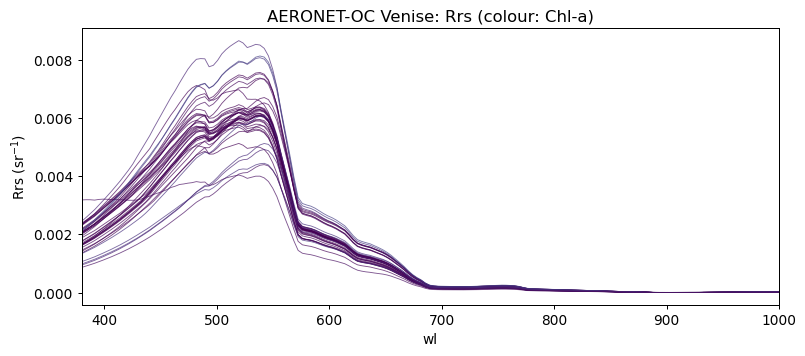

In [4]:
fig, ax = plt.subplots(figsize=(10, 4))
cmap = plt.cm.viridis
for i in range(inp.sizes['time']):
    c = cmap(np.log10(inp.chl_aeronet[i]) / 1.5)
    inp.Rrs.isel(time=i).plot(ax=ax, c=c, lw=.7, alpha=.7)
ax.set_xlim(380, 1000); ax.set_title(f'AERONET-OC {SITE}: Rrs (colour: Chl-a)'); ax.set_ylabel('Rrs (sr$^{-1}$)')

## 2. Simulation at the top of the atmosphere

In [5]:
%%time
toa = simulate_toa(inp, vza=(5., 20., 35.), azi=(90.,))
bands = to_sensors(toa)
toa

CPU times: user 19.3 s, sys: 2.93 s, total: 22.2 s
Wall time: 2min 4s


<xarray.Dataset> Size: 62MB
Dimensions:              (time: 40, wl: 21532, vza: 3, model: 6)
Coordinates:
  * time                 (time) datetime64[ns] 320B 2021-05-03T09:40:51 ... 2...
    aot_ref              (time) float64 320B 0.06316 0.06836 ... 0.05713 0.05525
    sza                  (time) float64 320B 34.48 31.48 30.39 ... 25.76 26.66
  * wl                   (wl) float64 172kB 350.1 350.3 ... 2.499e+03 2.5e+03
  * vza                  (vza) float64 24B 5.0 20.0 35.0
  * model                (model) <U9 216B 'ARCT_rh70' 'COAV_rh70' ... 'WASO_rh0'
Data variables: (12/16)
    Ed                   (time, wl) float64 7MB 681.0 644.5 ... 0.8877 7.279
    Ratm                 (time, vza, wl) float64 21MB 0.2437 ... 1.576e-05
    Rrs                  (time, wl) float64 7MB 0.001559 0.001562 ... 4.666e-09
    bbp_nir              (time) float64 320B 0.002809 0.003435 ... 0.001987
    E0                   (time, wl) float64 7MB 952.5 900.9 ... 44.59 44.6
    Rtoa                 (time, wl, vza) float64 21MB 0.2463 ... 1.576e-05
    ...                   ...
    aot550               (time) float64 320B 0.06316 0.06836 ... 0.05713 0.05525
    aot865               (time) float64 320B 0.03197 0.03447 ... 0.03569 0.03548
    ang_exp              (time) float64 320B 1.504 1.512 1.327 ... 1.039 0.9782
    wind                 (time) float64 320B 1.403 1.322 1.106 ... 5.127 5.355
    aerosol_combination  (model) float64 48B 0.0 0.5 0.0 0.5 0.0 0.0
    D2                   (time) float64 320B 0.983 0.983 0.983 ... 0.9763 0.9763
Attributes:
    radcalnet_oc_version:  1.1.0+gcad7591
    o2_model:              lbl
    gas_coupling:          path_length
    gas_coupling_table:    gas_coupling_ppld.csv
    rrs_extension:         pure_water
    rayleigh_pressure:     1
    solar_database:        tsis
    default_wind:          2.0
    toa_lut:               toa_lut_opac_wind_v3.nc
    toa_lut_doi:           10.5281/zenodo.23394202

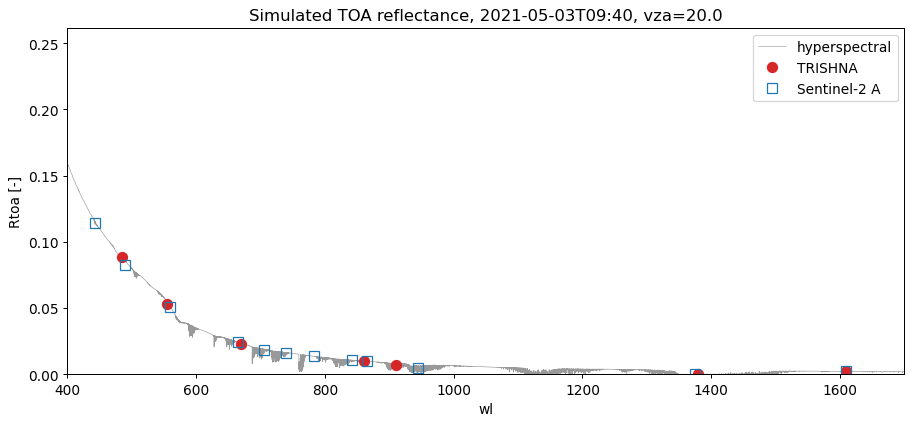

In [6]:
i, v = 0, 1  # record, viewing angle index
fig, ax = plt.subplots(figsize=(12, 5))
toa.Rtoa.isel(time=i, vza=v).squeeze().plot(ax=ax, c='0.6', lw=.5, label='hyperspectral')
for name, mk, c in [('TRISHNA', 'o', 'tab:red'), ('Sentinel-2 A', 's', 'tab:blue')]:
    r = bands[name].Rtoa.isel(time=i, vza=v).squeeze()
    ax.plot(r.wl, r, mk, c=c, ms=8, mfc='none' if mk == 's' else c, label=name)
ax.set_xlim(400, 1700); ax.set_ylim(0, None); ax.legend()
ax.set_title(f'Simulated TOA reflectance, {str(toa.time.values[i])[:16]}, vza={float(toa.vza[v])}')
fig.savefig(THUMB_DIR / 'toa_simulation_radcalnet_oc.png', dpi=70)

## 3. Sentinel-2 -> TRISHNA band adjustment at TOA
Factors fitted on the simulated TOA spectra (all records and angles). Contrary to the water
reflectance (see *Water quality products with TRISHNA*), the TOA factors vary little from one
case to another (narrow 95 % range) because the atmospheric signal dominates; the Blue factor
(~1.08) comes from the bluer TRISHNA band seeing more Rayleigh scattering. The cirrus band has
no factor here: its TOA signal is ~0 for clear-sky simulations. The WV factor (B9 945 nm -> 910 nm) is large and
depends on the water vapour: **a S2 B9 value is not a TRISHNA WV value**.

In [7]:
spec = toa.Rtoa.squeeze().stack(sample=[d for d in toa.Rtoa.squeeze().dims if d != 'wl']).transpose('sample', 'wl')
spec = spec.drop_vars([c for c in spec.coords if c not in ('wl',)])
SBAF(spec).table()

,s2,a,b,mdape_raw,mdape_adjusted,p95_ratio,n
Blue,B2,1.076042,0.0,0.070668,0.002652,"[1.065, 1.086]",120
Green,B3,1.063601,0.0,0.059798,0.002979,"[1.055, 1.072]",120
Red,B4,0.961427,0.0,0.040121,0.00143,"[0.959, 0.964]",120
NIR,B8A,1.013097,0.0,0.012927,0.002244,"[1.005, 1.017]",120
WV,B9,1.628875,0.0,0.386079,0.034061,"[1.53, 1.789]",120
Cirrus,B10,NaN,0.0,NaN,NaN,None,0
SWIR,B11,1.008207,0.0,0.008141,0.000553,"[1.007, 1.009]",120


## 4. Sensitivity to the aerosol optical thickness and water vapour
One Rrs spectrum is simulated for a grid of AOT(550) and TCWV in a single run. The water
contribution at TOA is `Rtoa - Ratm`.

In [8]:
%%time
grid = sensitivity_grid(inp.Rrs.isel(time=0), sza=float(inp.sza[0]),
                        aot=(0.02, 0.05, 0.1, 0.2, 0.4), tcwv=(5., 15., 30., 50.), vza=(20.,), azi=(90.,))
gb = to_sensors(grid, variables=('Rtoa', 'Ratm'))['TRISHNA']
frac = ((gb.Rtoa - gb.Ratm) / gb.Rtoa).squeeze()

CPU times: user 3.44 s, sys: 58 ms, total: 3.49 s
Wall time: 3.71 s


Text(0.5, 1.0, '')

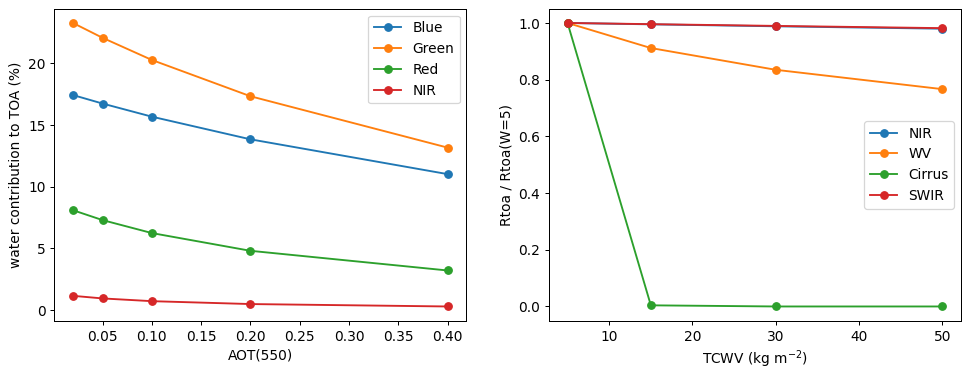

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
for b in ['Blue', 'Green', 'Red', 'NIR']:
    (100 * frac.sel(band=b, tcwv_sim=15.)).plot(ax=axs[0], marker='o', label=b)
axs[0].set_ylabel('water contribution to TOA (%)'); axs[0].set_xlabel('AOT(550)'); axs[0].legend(); axs[0].set_title('')
for b in ['NIR', 'WV', 'Cirrus', 'SWIR']:
    (gb.Rtoa.sel(band=b, aot550_sim=0.1).squeeze() / gb.Rtoa.sel(band=b, aot550_sim=0.1, tcwv_sim=5.).squeeze()
     ).plot(ax=axs[1], marker='o', label=b)
axs[1].set_ylabel('Rtoa / Rtoa(W=5)'); axs[1].set_xlabel('TCWV (kg m$^{-2}$)'); axs[1].legend(); axs[1].set_title('')

## 5. Sensitivity to the aerosol type
Same record with a single OPAC aerosol model (maritime clean vs urban vs desert).

In [10]:
%%time
one = inp.isel(time=[0])
res = {}
for m in ['MACL_rh70', 'URBA_rh70', 'DESE_rh70']:
    comb = [1. if a == m else 0. for a in AEROSOL_MODELS]
    t = simulate_toa(one, vza=(20.,), azi=(90.,), aerosol_combination=comb)
    res[m] = to_sensors(t, sensors=[TRISHNA])['TRISHNA'].Rtoa.squeeze().to_pandas()
df = pd.DataFrame(res)
df['urban - maritime (%)'] = 100 * (df['URBA_rh70'] - df['MACL_rh70']) / df['MACL_rh70']
df.round(4)

CPU times: user 10.2 s, sys: 591 ms, total: 10.8 s
Wall time: 1min 16s


,MACL_rh70,URBA_rh70,DESE_rh70,urban - maritime (%)
band,,,,
Blue,0.0886,0.0874,0.0866,-1.372400
Green,0.0532,0.0523,0.0525,-1.853800
Red,0.0232,0.0222,0.0234,-4.230500
NIR,0.0105,0.0090,0.0114,-14.881600
WV,0.0078,0.0064,0.0087,-18.264999
Cirrus,0.0000,0.0000,0.0000,-44.866299
SWIR,0.0028,0.0012,0.0043,-54.983200


## Take-home messages
- RadCalNet-OC propagates any water reflectance (in situ or simulated) to TOA for any band set,
  with the measured atmosphere: the basis for TRISHNA band-adjustment, noise and algorithm tests.
- In the blue, the water signal is only ~10 % of the TOA signal for moderate aerosol loads:
  aerosol type and AOT errors dominate the uncertainty of the TRISHNA Blue Rrs.
- The 910 nm band is sensitive to water vapour without saturating; S2 B9 cannot stand for it.

## References
- RadCalNet-OC / radcalnet_oc documentation (Magellium).
- Zibordi, G. et al. (2009), AERONET-OC: a network for the validation of ocean color primary products, JTECH 26.